# Практическая работа №2: Исследование подгрупп сетей. Сети аффилированности.

Выполнил студент гр. 4385 Юферев Артём Сергеевич. Вариант №22.

## Цель работы

Овладеть навыками работы с математическими пакетами для исследования подгрупп в социальных сетях, а также моделирования, отображения
и анализа сетей аффилированности.

## Основные теоретические положения

**Социоматрица** — это квадратная матрица смежности \(A\) размера \(N \times N\), где элемент \(a_{ij} = 1\), если между акторами \(i\) и \(j\) существует связь, и \(a_{ij} = 0\) в противном случае. Для ненаправленных сетей матрица симметрична (\(a_{ij} = a_{ji}\)).

**Точка сочленения (articulation point)** — вершина, при удалении которой увеличивается число компонент связности графа. 

**Мост (bridge)** — ребро, при удалении которого граф распадается на две компоненты связности.

**Централизация сети** по Фриману показывает, насколько сеть похожа на "звезду". Вычисляется по формуле:
$$C = \frac{\sum_{i=1}^{N} (C_{\max} - C_i)}{\max \sum_{i=1}^{N} (C_{\max} - C_i)}$$
где \(C_i\) — центральность \(i\)-й вершины, \(C_{\max}\) — максимальное значение центральности в сети.

**k-ядро (k-core)** — максимальный подграф, в котором степень каждой вершины не меньше \(k\). Анализ k-ядер позволяет выделить плотное ядро сети (наиболее интегрированную подгруппу).

**Модулярность (Q)** — мера качества разбиения сети на сообщества. Вычисляется как:
$$Q = \frac{1}{2m} \sum_{i,j} \left( A_{ij} - \frac{k_i k_j}{2m} \right) \delta(c_i, c_j)$$
где \(m\) — общее число рёбер, \(k_i\) — степень вершины \(i\), \(A_{ij}\) — элемент матрицы смежности, \(\delta(c_i, c_j) = 1\), если вершины \(i\) и \(j\) принадлежат одному кластеру, и \(0\) иначе. Значения \(Q > 0.3\) считаются значимыми.

**Сеть аффилированности (двудольная сеть)** — граф \(G = (A \cup E, L)\), где \(A\) — множество акторов, \(E\) — множество событий, а \(L\) — множество рёбер, соединяющих акторов с событиями. Матрица инцидентности \(B\) имеет размер \(|A| \times |E|\), где \(b_{ij} = 1\), если актор \(i\) участвует в событии \(j\), и \(b_{ij} = 0\) иначе.

**Одномодальные проекции** двудольной сети:
- Матрица смежности сети совместного участия акторов: 
$$A_{\text{act}} = B B^T$$
- Матрица смежности сети перекрытия событий: 
$$A_{\text{ev}} = B^T B$$

**Плотность графа** — отношение числа существующих рёбер к максимально возможному. Для ненаправленного графа:
$$D = \frac{2m}{N(N-1)}$$
где \(m\) — число рёбер, \(N\) — число вершин.

**Логарифм отношения шансов (LOR)** для пары событий \(i\) и \(j\) показывает, насколько часто они встречаются вместе по сравнению со случайным ожиданием:
$$LOR_{ij} = \ln \left( \frac{n_{ij} \cdot (N - n_i - n_j + n_{ij})}{(n_i - n_{ij})(n_j - n_{ij})} \right)$$
где \(N\) — общее число акторов, \(n_i\) и \(n_j\) — размеры событий, \(n_{ij}\) — число акторов, состоящих одновременно в обоих событиях.

## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей на предмет подгрупп. Провести
исследование сети аффилированности CEO. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

**Первый пункт**

In [ ]:
library(igraph)

data <- read.csv("florentine_marital.csv", comment.char = "#", header = TRUE)
rownames(data) <- colnames(data)

g <- graph_from_adjacency_matrix(as.matrix(data), mode = "undirected", weighted = FALSE)
plot(g, layout = layout_with_fr)

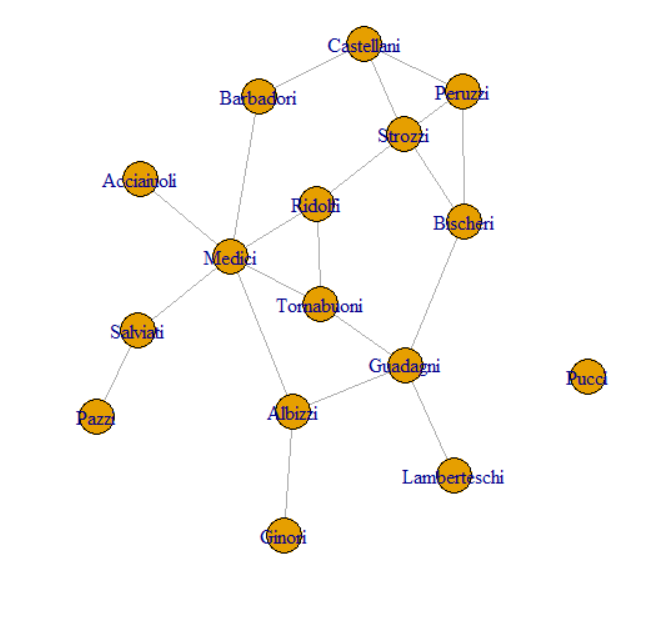

**Второй пункт**

In [ ]:
art <- articulation_points(g)
brdgs <- bridges(g)

vcol <- rep("orange", vcount(g))
vcol[art] <- "red"

ecol <- rep("grey", ecount(g))
ecol[brdgs] <- "red"

plot(g, layout = layout_with_fr, vertex.color = vcol, edge.color = ecol)

print(art)
print(brdgs)



Найденные точки сочленения : Albizzi, Guadagni Medici, Salviati                                         
                    Мосты :  Albizzi--Ginori, Guadagni--Lamberteschi, Pazzi--Salviati, Medici--Salviati, Acciaiuoli--Medici   
                    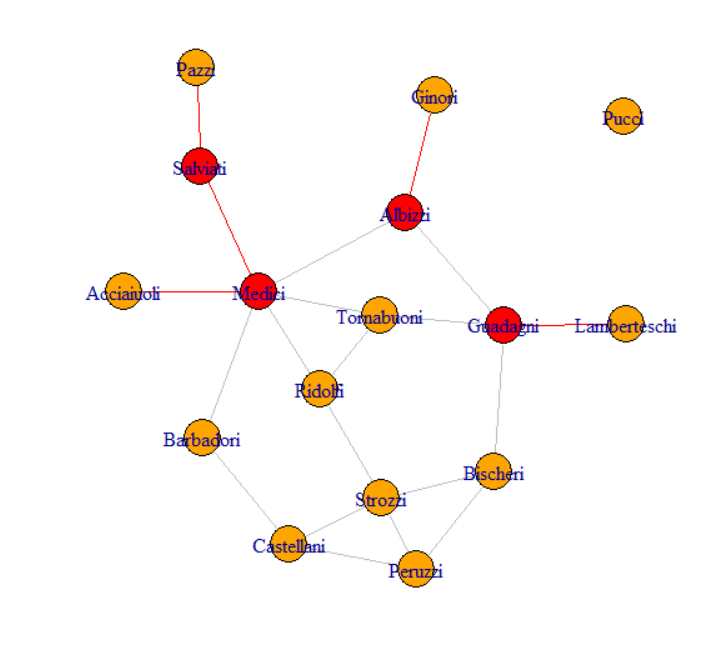


**Третий пункт**

In [ ]:
g2 <- delete_vertices(g, "Pucci")
eig <- eigen_centrality(g2)$vector

cent_deg  <- centralization.degree(g2)$centralization
cent_betw <- centralization.betweenness(g2)$centralization
cent_clos <- centralization.closeness(g2)$centralization
cent_eig  <- sum(max(eig) - eig) / ((vcount(g2) - 1) * (1 - 1/sqrt(vcount(g2) - 1))) / (vcount(g2) - 1)

print(c("Degree", "Betweenness", "Closeness", "Eigenvector"))
print(round(c(cent_deg, cent_betw, cent_clos, cent_eig), 4))



"Degree" - 0.2381,      
"Betweenness" -  0.4368,    
"Closeness" - 0.3225,   
"Eigenvector" - 0.0478

Сеть держится на «узких местах» вроде Medici. Также сеть не является "звездой", влияние распределено.

**Четвёртый пункт**

In [ ]:
core <- coreness(g)
print(core)

Максимальное ядро - 2-ядро : Albizzi, Barbadori, Bischeri, Castellani, Guadagni, Medici, Peruzzi, Ridolfi, Strozzi, Tornabuoni(связаны так, что у каждой минимум 2 связи внутри группы)

1-ядро : Acciaiuoli, Ginori, Lamberteschi, Pazzi, Salviati(связаны с 2-ядром одной связью)

0-ядро : Pucci (отдельная компонента)

В сети сформировано плотное 2-ядро из 10 семей, остальные 5 семей привязаны к этому ядру

**Пятый пункт**

In [ ]:
sg <- cluster_spinglass(g2)
print(sg)

wt <- cluster_walktrap(g2)

print(wt)

lp <- cluster_label_prop(g2)

print(lp)
print("Модулярность: ")
print(modularity(sg))
print(modularity(wt))
print(modularity(lp))
par(mfrow = c(1, 3))

plot(sg, g2, layout = layout_with_fr(g2), vertex.label = V(g2)$name, main = "Spinglass")

plot(wt, g2, layout = layout_with_fr(g2), vertex.label = V(g2)$name, main = "Walktrap")

plot(lp, g2, layout = layout_with_fr(g2), vertex.label = V(g2)$name, main = "Label propagation")

Алгоритмы: Spinglass, Walktrap, Label propagation.
Все три алгоритма показали высокие и практически идентичные значения модулярности, что показывает наличие выраженной кластерной структуры.

Суть алгоритмов:

Spinglass: ищет кластеры, минимизируя энергию связей между ними.

Walktrap: группирует вершины на основе того, как часто между ними проходят случайные пути

Label propagation: вершины перенимают самую частую метку соседей.

Модулярность: 

0.3975

0.3975

0.39875

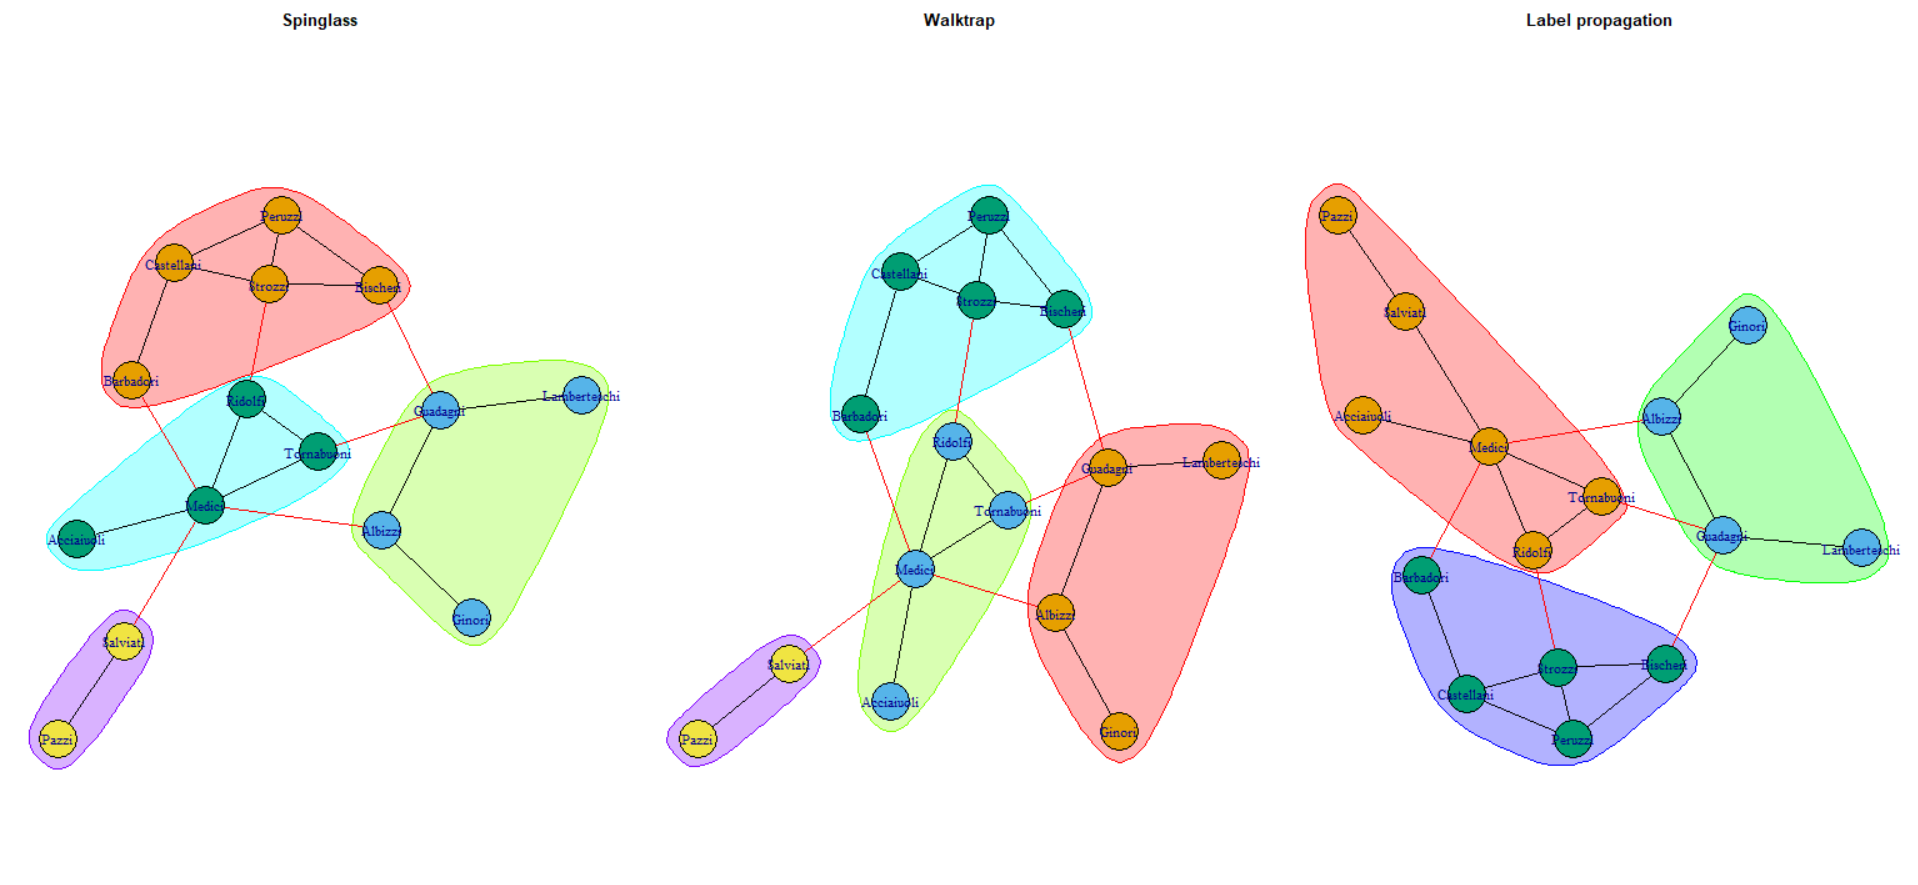

**Шестой пункт**

In [ ]:
ceo <- read.csv("ceo.csv", comment.char = "#", header = FALSE)

print(ceo)

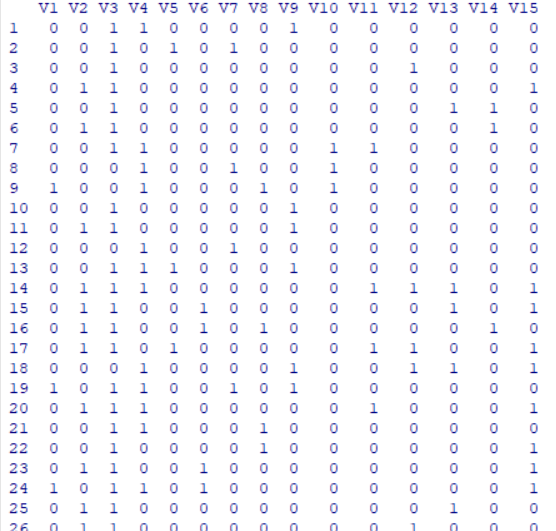

**Седьмой пункт**

In [ ]:
bg <- graph_from_incidence_matrix(as.matrix(ceo))
plot(bg, layout = layout_as_bipartite(bg))

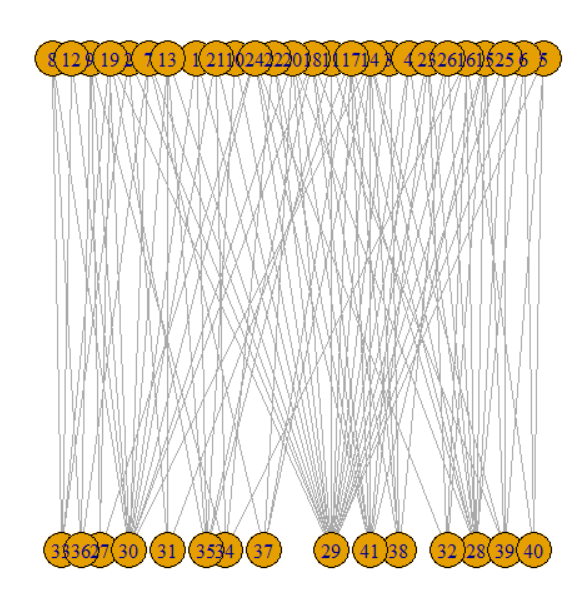

**Девятый пункт**

In [ ]:
A_actors <- as.matrix(ceo) %*% t(as.matrix(ceo))
A_events <- t(as.matrix(ceo)) %*% as.matrix(ceo)

diag(A_actors) <- 0
diag(A_events) <- 0
print(A_actors)
print(A_events)
g_actors <- graph_from_adjacency_matrix(A_actors, mode = 'undirected', weighted = TRUE)
g_events <- graph_from_adjacency_matrix(A_events, mode = 'undirected', weighted = TRUE)
par(mfrow = c(1, 2))
plot(g_actors, layout = layout_with_fr(g_actors, weights = E(g_actors)$weight), edge.label = E(g_actors)$weight)
plot(g_events, layout = layout_with_fr(g_events, weights = E(g_events)$weight), edge.label = E(g_events)$weight)

Матрица акторов
| V1 | V2 | V3 | V4 | V5 | V6 | V7 | V8 | V9 | V10 | V11 | V12 | V13 | V14 | V15 | V16 | V17 | V18 | V19 | V20 | V21 | V22 | V23 | V24 | V25 | V26 |
|----|----|----|----|----|----|----|----|----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|-----|
| 0  | 1  | 1  | 1  | 1  | 1  | 2  | 1  | 1  | 2   | 2   | 1   | 3   | 2   | 1   | 1   | 1   | 2   | 3   | 2   | 2   | 1   | 1   | 2   | 1   | 1   |
| 1  | 0  | 1  | 1  | 1  | 1  | 1  | 1  | 0  | 1   | 1   | 1   | 2   | 1   | 1   | 1   | 2   | 0   | 2   | 1   | 1   | 1   | 1   | 1   | 1   | 1   |
| 1  | 1  | 0  | 1  | 1  | 1  | 1  | 0  | 0  | 1   | 1   | 0   | 1   | 2   | 1   | 1   | 2   | 1   | 1   | 1   | 1   | 1   | 1   | 1   | 1   | 2   |
| 1  | 1  | 1  | 0  | 1  | 2  | 1  | 0  | 0  | 1   | 2   | 0   | 1   | 3   | 3   | 2   | 3   | 1   | 1   | 3   | 1   | 2   | 3   | 2   | 2   | 2   |
| 1  | 1  | 1  | 1  | 0  | 2  | 1  | 0  | 0  | 1   | 1   | 0   | 1   | 2   | 2   | 2   | 1   | 1   | 1   | 1   | 1   | 1   | 1   | 1   | 2   | 1   |
| 1  | 1  | 1  | 2  | 2  | 0  | 1  | 0  | 0  | 1   | 2   | 0   | 1   | 2   | 2   | 3   | 2   | 0   | 1   | 2   | 1   | 1   | 2   | 1   | 2   | 2   |
| 2  | 1  | 1  | 1  | 1  | 1  | 0  | 2  | 2  | 1   | 1   | 1   | 2   | 3   | 1   | 1   | 2   | 1   | 2   | 3   | 2   | 1   | 1   | 2   | 1   | 1   |
| 1  | 1  | 0  | 0  | 0  | 0  | 2  | 0  | 2  | 0   | 0   | 2   | 1   | 1   | 0   | 0   | 0   | 1   | 2   | 1   | 1   | 0   | 0   | 1   | 0   | 0   |
| 1  | 0  | 0  | 0  | 0  | 0  | 2  | 2  | 0  | 0   | 0   | 1   | 1   | 1   | 0   | 1   | 0   | 1   | 2   | 1   | 2   | 1   | 0   | 2   | 0   | 0   |
| 2  | 1  | 1  | 1  | 1  | 1  | 1  | 0  | 0  | 0   | 2   | 0   | 2   | 1   | 1   | 1   | 1   | 1   | 2   | 1   | 1   | 1   | 1   | 1   | 1   | 1   |
| 2  | 1  | 1  | 2  | 1  | 2  | 1  | 0  | 0  | 2   | 0   | 0   | 2   | 2   | 2   | 2   | 2   | 1   | 2   | 2   | 1   | 1   | 2   | 1   | 2   | 2   |
| 1  | 1  | 0  | 0  | 0  | 0  | 1  | 2  | 1  | 0   | 0   | 0   | 1   | 1   | 0   | 0   | 0   | 1   | 2   | 1   | 1   | 0   | 0   | 1   | 0   | 0   |
| 3  | 2  | 1  | 1  | 1  | 1  | 2  | 1  | 1  | 2   | 2   | 1   | 0   | 2   | 1   | 1   | 2   | 2   | 3   | 2   | 2   | 1   | 1   | 2   | 1   | 1   |
| 2  | 1  | 2  | 3  | 2  | 2  | 3  | 1  | 1  | 1   | 2   | 1   | 2   | 0   | 4   | 2   | 5   | 4   | 2   | 5   | 2   | 2   | 3   | 3   | 3   | 3   |
| 1  | 1  | 1  | 3  | 2  | 2  | 1  | 0  | 0  | 1   | 2   | 0   | 1   | 4   | 0   | 3   | 3   | 2   | 1   | 3   | 1   | 2   | 4   | 3   | 3   | 2   |
| 1  | 1  | 1  | 2  | 2  | 3  | 1  | 0  | 1  | 1   | 2   | 0   | 1   | 2   | 3   | 0   | 2   | 0   | 1   | 2   | 2   | 2   | 3   | 2   | 2   | 2   |
| 1  | 2  | 2  | 3  | 1  | 2  | 2  | 0  | 0  | 1   | 2   | 0   | 2   | 5   | 3   | 2   | 0   | 2   | 1   | 4   | 1   | 2   | 3   | 2   | 2   | 3   |
| 2  | 0  | 1  | 1  | 1  | 0  | 1  | 1  | 1  | 1   | 1   | 1   | 2   | 4   | 2   | 0   | 2   | 0   | 2   | 2   | 1   | 1   | 1   | 2   | 1   | 1   |
| 3  | 2  | 1  | 1  | 1  | 1  | 2  | 2  | 2  | 2   | 2   | 2   | 3   | 2   | 1   | 1   | 1   | 2   | 0   | 2   | 2   | 1   | 1   | 3   | 1   | 1   |
| 2  | 1  | 1  | 3  | 1  | 2  | 3  | 1  | 1  | 1   | 2   | 1   | 2   | 5   | 3   | 2   | 4   | 2   | 2   | 0   | 2   | 2   | 3   | 3   | 2   | 2   |
| 2  | 1  | 1  | 1  | 1  | 1  | 2  | 1  | 2  | 1   | 1   | 1   | 2   | 2   | 1   | 2   | 1   | 1   | 2   | 2   | 0   | 2   | 1   | 2   | 1   | 1   |
| 1  | 1  | 1  | 2  | 1  | 1  | 1  | 0  | 1  | 1   | 1   | 0   | 1   | 2   | 2   | 2   | 2   | 1   | 1   | 2   | 2   | 0   | 2   | 2   | 1   | 1   |
| 1  | 1  | 1  | 3  | 1  | 2  | 1  | 0  | 0  | 1   | 2   | 0   | 1   | 3   | 4   | 3   | 3   | 1   | 1   | 3   | 1   | 2   | 0   | 3   | 2   | 2   |
| 2  | 1  | 1  | 2  | 1  | 1  | 2  | 1  | 2  | 1   | 1   | 1   | 2   | 3   | 3   | 2   | 2   | 2   | 3   | 3   | 2   | 2   | 3   | 0   | 1   | 1   |
| 1  | 1  | 1  | 2  | 2  | 2  | 1  | 0  | 0  | 1   | 2   | 0   | 1   | 3   | 3   | 2   | 2   | 1   | 1   | 2   | 1   | 1   | 2   | 1   | 0   | 2   |
| 1  | 1  | 2  | 2  | 1  | 2  | 1  | 0  | 0  | 1   | 2   | 0   | 1   | 3   | 2   | 2   | 3   | 1   | 1   | 2   | 1   | 1   | 2   | 1   | 2   | 0   |

Матрица событий
| V1 | V2 | V3 | V4 | V5 | V6 | V7 | V8 | V9 | V10 | V11 | V12 | V13 | V14 | V15 |
|----|----|----|----|----|----|----|----|----|-----|-----|-----|-----|-----|-----|
| 0  | 0  | 2  | 3  | 0  | 1  | 1  | 1  | 1  | 1   | 0   | 0   | 0   | 0   | 1   |
| 0  | 0  | 11 | 2  | 1  | 3  | 0  | 1  | 1  | 0   | 3   | 3   | 3   | 2   | 6   |
| 2  | 11 | 0  | 8  | 3  | 4  | 2  | 3  | 5  | 1   | 4   | 4   | 4   | 3   | 8   |
| 3  | 2  | 8  | 0  | 1  | 1  | 3  | 2  | 4  | 3   | 3   | 2   | 2   | 0   | 4   |
| 0  | 1  | 3  | 1  | 0  | 0  | 1  | 0  | 1  | 0   | 1   | 1   | 0   | 0   | 1   |
| 1  | 3  | 4  | 1  | 0  | 0  | 0  | 1  | 0  | 0   | 0   | 0   | 1   | 1   | 3   |
| 1  | 0  | 2  | 3  | 1  | 0  | 0  | 0  | 1  | 1   | 0   | 0   | 0   | 0   | 0   |
| 1  | 1  | 3  | 2  | 0  | 1  | 0  | 0  | 0  | 1   | 0   | 0   | 0   | 1   | 1   |
| 1  | 1  | 5  | 4  | 1  | 0  | 1  | 0  | 0  | 0   | 0   | 1   | 1   | 0   | 1   |
| 1  | 0  | 1  | 3  | 0  | 0  | 1  | 1  | 0  | 0   | 1   | 0   | 0   | 0   | 0   |
| 0  | 3  | 4  | 3  | 1  | 0  | 0  | 0  | 0  | 1   | 0   | 2   | 1   | 0   | 3   |
| 0  | 3  | 4  | 2  | 1  | 0  | 0  | 0  | 1  | 0   | 2   | 0   | 2   | 0   | 3   |
| 0  | 3  | 4  | 2  | 0  | 1  | 0  | 0  | 1  | 0   | 1   | 2   | 0   | 1   | 3   |
| 0  | 2  | 3  | 0  | 0  | 1  | 0  | 1  | 0  | 0   | 0   | 0   | 1   | 0   | 0   |
| 1  | 6  | 8  | 4  | 1  | 3  | 0  | 1  | 1  | 0   | 3   | 3   | 3   | 0   | 0   |

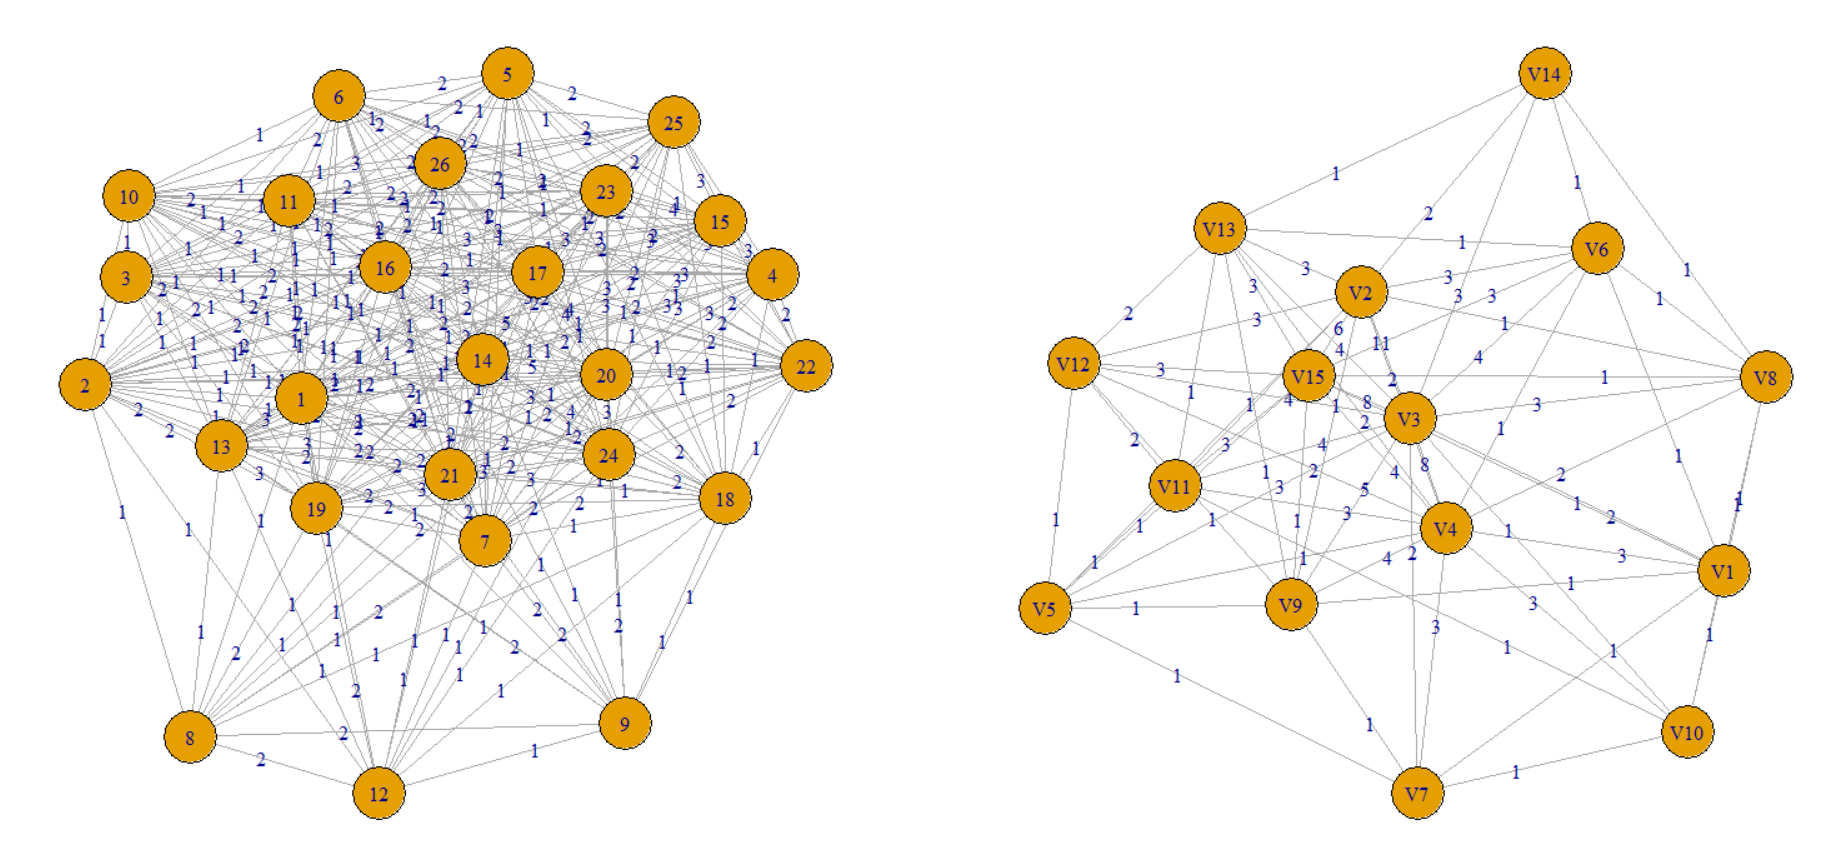

Сеть акторов очень плотная. Но вершины 8,12,9 явно имеют мало связей и веса в основном 1.                       
Сеть событий имеет чёткое ядро(V11, V15, V2, V3, V4), а остальные вершины находятся на периферии с малыми весами

**Десятый пункт**

In [ ]:
deg <- rowSums(as.matrix(ceo))
avg_events <- mean(deg)

print(deg)
print(avg_events)

степень участия для каждого актора  3 3 2 3 3 3 4 3 4 2 3 2 4 7 5 5 6 5 5 5 3 3 4 5 3 3                         
среднее количество событий 3.769231

Есть небольшое ядро сверхактивных участников и более пассивная периферия.

**Одиннадцать пункт**

In [ ]:
event_size <- colSums(as.matrix(ceo))
avg_size <- mean(event_size)

print(event_size)
print(avg_size)

Размер

3  11  22  12   3   4   4   4   6   3   4   5   5   3   9 (V1-V15 соответственно)

Средний размер 6.

Выделяется одно сверхпопулярное событие V3 с 22 участниками, которое объединяет почти всех акторов, в то время как остальные значительно меньше.

**Двенадцатый пункт**

In [ ]:
dens_act <- edge_density(g_actors)
dens_ev  <- edge_density(g_events)

print(dens_act)
print(dens_ev)

плотность для отношения совместного участия акторов 0.8738462                       
 плотность для отношения перекрытия 0.6285714

Плотность сети совместного участия акторов значительно выше плотности сети перекрытия событий. почти каждый актор имеет хотя бы одно общее событие с любым другим. События пересекаются реже.

**Тринадцатый пункт**

In [ ]:
diam <- diameter(bg, directed = FALSE)
print(diam)

Диаметр 5

**Четырнадцатый пункт**

In [ ]:
N <- nrow(as.matrix(ceo))
A_log <- matrix(0, nrow = 15, ncol = 15)

for (i in 1:15){
    for (j in 1:15)
    {
        if (i<j) {
            nij <- sum(as.matrix(ceo)[, i] & as.matrix(ceo)[, j])
            ni <- event_size[i]
            nj <- event_size[j]

            a <- nij
            b <- (ni - nij)
            c1 <- (nj - nij)
            d <- (N - ni - nj + nij)

            loga <- log((a*d)/(b*c1))
            A_log[i, j] <- loga
            A_log[j, i] <- loga

        }
    }
}
print(A_log)

|    | V1                  | V2                 | V3                 | V4                 | V5                  | V6                | V7                | V8                 | V9                 | V10               | V11               | V12                | V13                | V14               | V15                 |
|----|---------------------|--------------------|--------------------|--------------------|---------------------|-------------------|-------------------|--------------------|--------------------|-------------------|-------------------|--------------------|--------------------|-------------------|---------------------|
| 1  | 0                   | -Inf               | -1.20397280432594  | Inf                | -Inf                | 1.20397280432594  | 1.20397280432594  | 1.20397280432594   | 0.587786664902119  | 1.65822807660353  | -Inf              | -Inf               | -Inf               | -Inf              | -0.0645385211375712 |
| 2  | -Inf                | 0                  | Inf                | -2.19722457733622  | -0.430782916092454  | 1.65822807660353  | -Inf              | -0.916290731874155 | -1.6094379124341   | -Inf              | 1.65822807660353  | 0.890972923889865  | 0.890972923889865  | 1.13497993283898  | 1.56861591791385    |
| 3  | -1.20397280432594   | Inf                | 0                  | -Inf               | Inf                 | Inf               | -2.30258509299405 | -0.747214401830221 | -0.125163142954006 | -3.04452243772342 | Inf               | -0.405465108108164 | -0.405465108108164 | Inf               | 0.538996500732687   |
| 4  | Inf                 | -2.19722457733622  | -Inf               | 0                  | -0.606135803570316  | -1.09861228866811 | 1.46633706879343  | 0.182321556793955  | 1.09861228866811   | Inf               | 1.46633706879343  | -0.31015492830384  | -0.31015492830384  | -Inf              | -0.105360515657826  |
| 5  | -Inf                | -0.430782916092454 | Inf                | -0.606135803570316 | 0                   | -Inf              | 1.20397280432594  | -Inf               | 0.587786664902119  | -Inf              | 1.20397280432594  | 0.864997437486605  | -Inf               | -Inf              | -0.0645385211375712 |
| 6  | 1.20397280432594    | 1.65822807660353   | Inf                | -1.09861228866811  | -Inf                | 0                 | -Inf              | 0.747214401830221  | -Inf               | -Inf              | -Inf              | -Inf               | 0.405465108108164  | 1.20397280432594  | 2.07944154167984    |
| 7  | 1.20397280432594    | -Inf               | -2.30258509299405  | 1.46633706879343   | 1.20397280432594    | -Inf              | 0                 | -Inf               | 0.125163142954006  | 1.20397280432594  | -Inf              | -Inf               | -Inf               | -Inf              | -Inf                |
| 8  | 1.20397280432594    | -0.916290731874155 | -0.747214401830221 | 0.182321556793955  | -Inf                | 0.747214401830221 | -Inf              | 0                  | -Inf               | 1.20397280432594  | -Inf              | -Inf               | -Inf               | 1.20397280432594  | -0.538996500732687  |
| 9  | 0.587786664902119   | -1.6094379124341   | -0.125163142954006 | 1.09861228866811   | 0.587786664902119   | -Inf              | 0.125163142954006 | -Inf               | 0                  | -Inf              | -Inf              | -0.22314355131421  | -0.22314355131421  | -Inf              | -1.20397280432594   |
| 10 | 1.65822807660353    | -Inf               | -3.04452243772342  | Inf                | -Inf                | -Inf              | 1.20397280432594  | 1.20397280432594   | -Inf               | 0                 | 1.20397280432594  | -Inf               | -Inf               | -Inf              | -Inf                |
| 11 | -Inf                | 1.65822807660353   | Inf                | 1.46633706879343   | 1.20397280432594    | -Inf              | -Inf              | -Inf               | -Inf               | 1.20397280432594  | 0                 | 1.84582669049833   | 0.405465108108164  | -Inf              | 2.07944154167984    |
| 12 | -Inf                | 0.890972923889865  | -0.405465108108164 | -0.31015492830384  | 0.864997437486605   | -Inf              | -Inf              | -Inf               | -0.22314355131421  | -Inf              | 1.84582669049833  | 0                  | 1.38629436111989   | -Inf              | 1.32175583998232    |
| 13 | -Inf                | 0.890972923889865  | -0.405465108108164 | -0.31015492830384  | -Inf                | 0.405465108108164 | -Inf              | -Inf               | -0.22314355131421  | -Inf              | 0.405465108108164 | 1.38629436111989   | 0                  | 0.864997437486605 | 1.32175583998232    |
| 14 | -Inf                | 1.13497993283898   | Inf                | -Inf               | -Inf                | 1.20397280432594  | -Inf              | 1.20397280432594   | -Inf               | -Inf              | -Inf              | -Inf               | 0.864997437486605  | 0                 | -Inf                |
| 15 | -0.0645385211375712 | 1.56861591791385   | 0.538996500732687  | -0.105360515657826 | -0.0645385211375712 | 2.07944154167984  | -Inf              | -0.538996500732687 | -1.20397280432594  | -Inf              | 2.07944154167984  | 1.32175583998232   | 1.32175583998232   | -Inf              | 0                   |

 Матрица показывает, что одни события полностью дублируют друг друга по составу, а другие вообще не имеют общих участников (-Inf). Это значит, что часть событий пересекается, а часть существует абсолютно обособленно друг от друга.

## Выводы

В ходе выполнения практической работы были освоены методы математического анализа социальных сетей с использованием возможностей языка R и библиотеки igraph. Были исследованы две модели: классическая сеть брачных связей флорентийских семей и двудольная сеть аффилированности CEO корпораций.

*Анализ сети семей*:
Сеть состоит из 16 вершин, однако вершина Pucci является изолированной, что делает общий граф несвязным. Анализ точек сочленения и мостов показал, что сеть имеет явные узкие места (Medici и Guadagni), удаление которых разрывает связи между целыми кланами.
Расчёт централизации подтвердил, что сеть имеет высокую степень централизации вокруг клана Medici (лидирует по всем мерам). Анализ k-ядер выявил плотное ядро(2) из 10 семей, куда вошли Medici и их ближайшие союзники.

*Анализ сети аффилированности*:
Сеть была представлена в виде биграфа (26 акторов и 15 событий). Проекция в две сети показала высокую плотность, что означает, что есть очень сплочённое сообщество, где практически каждый CEO пересекается с каждым.

Анализ степеней участия показал, что среднее количество клубов на одного CEO составляет около 3.769231, а размеры событий в среднем 6.533333. Диаметр сети оказался очень малым.